# Material Balances XVIII

[What is Bond listening to right now](https://www.youtube.com/watch?v=FSfwmlRqdHQ&list=RDFSfwmlRqdHQ&start_radio=1)

This Notebook considers design of and applications for membrane reactors. It specifically considers the use of a membrane reactor to mitigate the challenging equilibrium limitation in propane dehydrogenation. Previously, we considered how one might use product separation and reactant recycle to achieve high overall conversions. Membrane reactors are an alternative strategy for product removal to drive high conversions of propane despite unfavorable thermodyanmics. This Notebook also introduces the Ergun Equation for calculating pressure differentials across packed bed reactors.

## Recap: Working with Equilibrium Constraints in Propane Dehydrogenation

In the last few Notebooks ([Notebook 33](https://jqbond.github.io/CEN587/Notebooks/587-N33.html), [Notebook 34](https://jqbond.github.io/CEN587/Notebooks/587-N34.html), and [Notebook 35](https://jqbond.github.io/CEN587/Notebooks/587-N35.html)), we have considered in detail the impact of equilibrium limitations for a thermodynamically unfavorable reaction like propane dehydrogenation at 500K. To this point, we have considered:

1. [Decreasing pressure and adding a diluent to allow high single pass conversions](https://jqbond.github.io/CEN587/Notebooks/587-N33.html#example-problem-03). This will work, but it requires a very large reactor $(V \approx 30,000\mathrm{L})$.
2. [Adding a separator, splitter, and mixer and operating the PFR with recycle](https://jqbond.github.io/CEN587/Notebooks/587-N34.html#example-problem-01). This will allow us to operate the PFR at relatively low single pass conversions, giving a relatively small reactor $(V \approx 250L)$, but we have to invest in separations and recycle, which will add considerable to captial and operating costs. 

Now, we'll consider the use of a membrane reactor for propane dehydrogenation. Membrane reactors can be useful for reactions where selectivity control is challenging, and they can also help to mitigate equilibrium constraints if we design them for product removal. This is the strategy that we will use for propane dehydrogenation in this Notebook.  

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

## Example Problem 01

We will carry out propane dehydrogenation in a membrane reactor. Specifically we will design our reactor such that there is an internal tube into which we feed pure propane at $P = 8.2 \ \mathrm{atm}$ and a flowrate of $F_{A0} = 10 \ \mathrm{mol \ min^{-1}}$. This internal tube is surrounded by an external tube into which we feed pure $N_2$ at 1 atm and a very high flowrate. A key detail about this membrane reactor is that the wall of the inner tube is made from a special, porous membrane that allows $H_2$ diffusion across the membrane (out of the inner tube), but will not allow diffusion of any other component. In this configuration, the pressure of $H_2$ inside of the inner reactor is always higher than the pressure of $H_2$ in the annulus, so $H_2$ will diffuse out of the reactor and into the annulus, where it is rapidly diluted by $N_2$. Because we are using a very high $N_2$ flowrate in the annulus, we can assume that the concentration (partial pressure) of $H_2$ in the annulus is always approximately zero, even though $H_2$ is continuously diffusing out of the reactor and into the annulus. 

```{important}
Since we're removing a product $(H_2)$, we do not need to feed a diluent or reduce pressure to achieve the desired 95\% conversion of propane in a single pass!  
```

Rate and equilibrium constants remain the same because we haven't changed the temperature. We are additionally given a lumped mass transfer coefficient that describes the rate of $H_2$ diffusion across the membrane.
		
\begin{align}
    k_f  &= 0.7  \ \textrm{min}^{-1} \\
    K_C &= 0.05 \ \textrm{mol} \ \textrm{L}^{-1}\\
    k_{C_C}a &= 0.2 \ \textrm{min}^{-1}				
\end{align}			

How large does this membrane reactor need to be to achieve 95\% conversion of propane?

### A Review of the PFR Balance

Recall from [Notebook 15](https://jqbond.github.io/CEN587/Notebooks/587-N15.html) how we originally developed the PFR balance by considering a single cross sectional element with a volume of $\Delta V$. In the case of a PFR, we assume that inside of that cross section has a uniform Temperature, Pressure, Composition (and therefore reaction rate). So, within that uniform cross section, the rate of generation or consumption by chemical reaction, $G_j$, is given by:

$$G_j = R_j\Delta V$$

If the PFR is operating at steady state, we can write a balance on that well-mixed cross section:

$$ 0 = F_j\big|_V - F_j\big|_{V+\Delta V} + R_j \Delta V$$

Next, we divide the whole equation by $\Delta V$:

$$ 0 = \frac{F_j\big|_V - F_j\big|_{V+\Delta V}}{\Delta V} + R_j$$

We next assume that the PFR is comprised of an an infinite number of cross sections, which means that the volume of each cross section approaches zero, i.e., $\Delta V \longrightarrow 0$.  This is essentially the definition of a derivative, which gives:

$$ 0 = -\frac{dF_j}{dV} + R_j$$

In PFR analysis, we typically rearrange this equation to get:

$$\frac{dF_j}{dV} = R_j$$

### Modifying the PFR balance to model a membrane reactor

When we have a membrane reactor, we modify the PFR balance slightly to allow that species $j$ can diffuse into or out of the well-mixed volume element, $\Delta V$.  We define the rate of diffusion across the membrane ***per unit volume of reactor*** as:

$$\bar{R}_j = W_j \, a$$

Here, $W_j$ is the flux of species $j$ across the membrane and $a$ is the ratio of surface area to volume for that membrane.  

#### Units in the Membrane Reactor Balance

We need to discuss dimensions.  $\bar{R_j}$ will have the same units as our intensive reaction rates, $r_i$ and our intensive species production rates, $R_j$.  For example:

$$\bar{R}_j \ [=]\ \mathrm{\frac{mol}{m^3 \, s}}$$

We recall from heat and mass transfer that fluxes have units of moles per area per time; for example:

$$W_j \ [=] \ \mathrm{\frac{mol}{m^2 \, s}}$$

And the surface area to volume ratio, $a$ will have units of area per volume, which reduces to inverse length, for example:

$$a = \mathrm{\frac{Area}{Volume}} \ [=] \ \frac{m^2}{m^3} \ [=] \ \frac{1}{m}$$

With these definitions and unit conventions in mind, we see that the product of $W_j a$ gives the correct units on $\bar{R}_j$:

$$\bar{R}_j = W_j \, a \ [=] \ \mathrm{\frac{mol}{m^2 \, s}} \ \frac{1}{m} \ [=] \ \mathrm{\frac{mol}{m^3 \, s}}$$

#### The steady state balance on a well-mixed volume element in a membrane reactor

With the above in mind, we can write the following balance to describe flow in, flow out, and reaction into the well-mixed volume element, $\Delta V$:

$$ 0 = F_j\big|_V - F_j\big|_{V+\Delta V} + R_j \Delta V + \bar{R}_j \Delta V$$

Dividing the equation through by $\Delta V$ and allowing $\Delta V \rightarrow \infty$ gives the membrane reactor balance:

$$\frac{dF_j}{dV} = R_j + \bar{R}_j$$

#### Defining the diffusion rate

Now that we have a general balance, the only thing that remains is to express the diffusion rate in terms of species concentrations (or partial pressures) similar to the way we have always expressed intensive production rates in terms of species concentrations (or partial pressures). From our courses in heat and mass transer, we can recall that flux across a boundary can be calculated as:

$$W_j = k_{C_j}(C_{j_s} - C_j)$$

In the context of the membrane reactor, consistent with sign conventions on flowrates and production rates, we define flux ***into the reactor*** as positive and ***out of the reactor*** as negative. $k_{C_j}$ is a mass transfer coefficient for species $j$; $C_{j_s}$ is the concentration of species $j$ in the annular ***space*** surrounding the inner reactor tube, and $C_j$ is the concentration of species $j$ inside of the reactor. We can see that in cases where $C_j > C_{j_s}$, diffusion will occur from the reactor to the annulus and have a negative sign. Mass transfer coefficients always have units of length-per-time, thus the product of $k_{C_j}$ and concentration gives a flux in the correct units of moles per area per time.

For a cylinder such as this membrane reactor, the ratio of area to volume is:

$$a = \frac{2 \pi r L}{\pi r^2 L} = \frac{2}{r}$$

Ultimately, we can define the rate of diffusion across the membrane as:

$$\bar{R}_j = k_{C_j}a(C_{j_s} - C_j)$$

And we note that the product $k_{C_j}a$ is frequently lumped and given in problem statements (such as this one).

### Solution to Example Problem 01

With the above derivations for membrane reactor balances in mind, we can write material balances for all 3 species in this reactor:

\begin{align}
    \frac{dF_A}{dV} &= R_A \\
    \frac{dF_B}{dV} &= R_B \\
    \frac{dF_C}{dV} &= R_C + \bar{R}_C\\
\end{align}

Next, we begin the usual steps of defining the right hand side of each ODE in terms of constants, state variables, and the independent variable (V):

\begin{align}
    R_A &= -r \\
    R_B &=  r \\
    R_C &=  r 
\end{align}

We know that this reaction has elementary kinetics so:

$$r = k_fC_A - k_rC_BC_C$$

Concentrations can be defined in terms of flowrates:

\begin{align}
    C_A &= F_A/Q \\
    C_B &= F_B/Q \\
    C_C &= F_C/Q 
\end{align}

Where:

$$Q = \frac{F_T R T}{P}$$

And:

$$F_T = F_A + F_B + F_C$$

Finally:

$$\bar{R}_j = k_{C_C}a(C_{C_s} - C_C)$$

The lumped mass transfer coefficient/area product is given in the problem statement, and we can assume that the concentration of C in the annular space is zero due to the large excess of $N_2$ in the annulus.  With that, we can solve the problem using `solve_ivp()`.

The Membrane Reactor Volume required for XA = 0.95 is 3054L


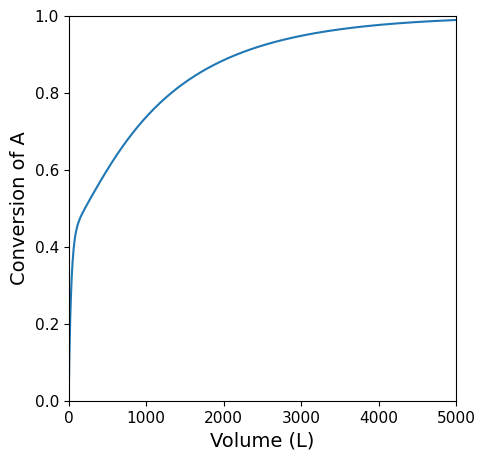

In [2]:
#############################################################################
# Defining global constants for Example Problem 01                          #
#############################################################################

kf  = 0.7  #1/min
KC  = 0.05 #mol/L
kr  = kf/KC #L/mol/min
kca = 0.2 #1/min
CCs = 0.0
T   = 500 #K
P   = 8.2 #atm
R   = 0.08206 #L*atm/mol/K
FA0 = 10.0 #mol/min
FB0 = 0.0
FC0 = 0.0
XA_target = 0.95

#############################################################################
# Define the system of ODEs that describe this membrane reactor             #
# Function has the form f(V, [FA, FB, FC])                                  #
# It returns [dFAdV, dFBdV, dFCdV]                                          #
#############################################################################

def P01(V, var):
    FA, FB, FC = var   
    FT = FA + FB + FC
    Q  = FT*R*T/P
    CA = FA/Q
    CB = FB/Q
    CC = FC/Q
    r  = kf*CA - kr*CB*CC
    RA = -r
    RB =  r
    RC =  r
    RCbar = kca*(CCs - CC)
    dA = RA
    dB = RB
    dC = RC + RCbar
    return [dA, dB, dC]

#############################################################################
# Set integration span and initial state of the system                      #
#############################################################################

# Vspan = (0.0, 100.0)
Vspan = (0.0, 5000.0)
var0  = (FA0, FB0, FC0)
ans2  = solve_ivp(P01, Vspan, var0, atol = 1e-8, rtol =  1e-8)

#############################################################################
# Extract flowrate information from the solution structure                  #
#############################################################################

V     = ans2.t
FA    = ans2.y[0]
FB    = ans2.y[1]
FC    = ans2.y[2]

#############################################################################
# Calculate fractional conversion of propane                                #
#############################################################################

XA    = (FA0 - FA)/FA0

#############################################################################
# Construct interpolating polynomial approximation for V(XA); find V(0.95)  #
#############################################################################

itp1 = interp1d(XA, V, kind = 'cubic')
Vopt = itp1(XA_target)
print(f'The Membrane Reactor Volume required for XA = {XA_target:0.2f} is {Vopt:0.0f}L')

#############################################################################
# Graph propane conversion vs. membrane reactor volume                      #
#############################################################################

plt.figure(figsize = (5, 5))
plt.plot(V, XA)
plt.xlim(0.0, max(Vspan))
plt.xticks(fontsize = 11)
plt.xlabel('Volume (L)', fontsize = 14)
plt.ylim(0.0, 1.0)
plt.yticks(fontsize = 11)
plt.ylabel('Conversion of A', fontsize = 14)
plt.show()

## Example Problem 02

Now let's consider packed bed reactor performance.  For this problem, we'll carry out ethylene hydrogenation (reaction 1). A side reaction, ethylene dimerization (reaction 2) also occurs under these conditions. Overall reactions for each are given below.

\begin{align*}
    C_2H_4 + H_2 &\longrightarrow C_2H_6 \\
    2C_2H_4 &\longrightarrow C_4H_8			
\end{align*}			

Both reactions occur in the gas phase, and each has an elementary rate law. Additional parameters and operating conditions are specified below.

\begin{align*}
    k_1  &= 10 \ \textrm{L}^{2} \ \textrm{mol}^{-1} \ \textrm{kg}^{-1} \ \textrm{sec}^{-1} \\
    k_2  &= 1 \ \textrm{L}^{2} \ \textrm{mol}^{-1} \ \textrm{kg}^{-1} \ \textrm{sec}^{-1} \\
    F_{A_f} &= 100 \ \textrm{mol} \ \textrm{sec}^{-1} \\				
    F_{B_f} &= 100 \ \textrm{mol} \ \textrm{sec}^{-1} \\
    T &= 573 \ \textrm{K} \\
    P &= 10 \ \textrm{bar}
\end{align*}			

If the reactor operates isobarically, calculate the mass of catalyst required to achieve an ethylene conversion of 70\%.

### Solution to Example Problem 02

We start by writing material balances on each species. Recall that in a packed bed, our independent variable is catalyst mass, $W$, and we report reaction rates per unit mass of catalyst, $r^\prime$.

\begin{align*}
    \frac{dF_A}{dW} &= {R_A}^\prime \\
    \frac{dF_B}{dW} &= {R_B}^\prime \\
    \frac{dF_C}{dW} &= {R_C}^\prime \\
    \frac{dF_D}{dW} &= {R_D}^\prime \\
\end{align*}

Where the prime ($^\prime$) superscript just means that intensive rates are specified per unit mass of catalyst.  Otherwise, intensive production rates are defined as usual.

\begin{align*}
    {R_A}^\prime &= -{r_1}^{\prime} -2{r_2}^{\prime} \\
    {R_B}^\prime &= -{r_1}^{\prime} \\
    {R_C}^\prime &= {r_1}^{\prime} \\
    {R_D}^\prime &= {r_2}^{\prime} \\
\end{align*}

These reactions have elementary kinetics, so:

\begin{align*}
    {r_1}^{\prime} &= k_1C_AC_B \\
    {r_2}^{\prime} &= k_2C_A^2 \\
\end{align*}

We define concentrations in terms of flowrates (dependent variables) as usual; technically, we only need concentrations for $A$ and $B$ to evaluate the rate expressions.:

\begin{align*}
    C_A &= F_A/Q \\
    C_B &= F_B/Q \\
\end{align*}

Since this is a gas-phase reaction at modest pressure (and we don't have a better equation of state on hand), we will define $Q$ using the ideal gas law:

$$Q = \frac{F_TRT}{P}$$

We know the reactor is isobaric, so the pressure in this reactor is always equal to 10 bar. At this point, everything on the right-hand side of our ODEs is defined in terms of constants and our state variables, so we can solve with `solve_ivp()`.

The mass of catalyst required to achieve XA = 0.70 is W = 957 kg


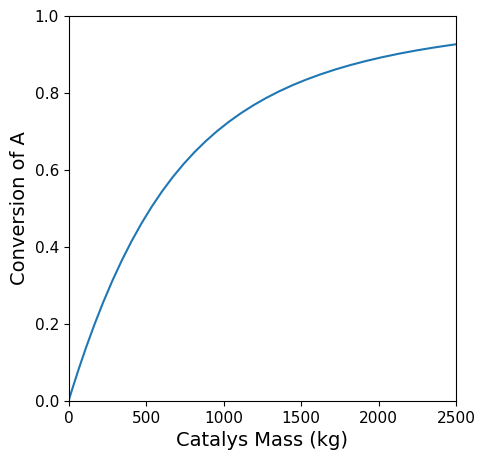

In [3]:
###################################################################
# Defining global constants for Example Problem 02                #
###################################################################

FAf = 100        #mol/s
FBf = 100        #mol/s
FCf = 0          #mol/s
FDf = 0          #mol/s
P   = 1.0e6      #Pa, 10 bar
R   = 8314       #L*Pa/mol/K
T   = 573        #K
k1  = 10         #L^2/mol/kg/sec
k2  = 1          #L^2/mol/kg/sec
XA_target = 0.7

###################################################################
# Define ODE system that describes the packed bed                 #
# function has the form f(W, [FA, FB, FC, FD])                    #
# function returns [dFAdW, dFBdW, dFCdW, dFDdW]                   #
###################################################################

def P02(W, var):
    FA, FB, FC, FD = var #all flowrates in mol/s
    
    FT = FA + FB + FC + FD
    Q  = FT*R*T/P       #vol flow rate, L/sec
    CA = FA/Q          #Concentration of A, mol/L
    CB = FB/Q          #Concentration of B, mol/L
    r1 = k1*CA*CB      #Rate of reaction 1, mol/kg/sec
    r2 = k2*CA**2      #Rate of reaction 2, mol/kg/sec
    RA = -r1 - 2*r2
    RB = -r1
    RC =  r1
    RD =  r2
    
    dFAdW = RA
    dFBdW = RB
    dFCdW = RC
    dFDdW = RD
    return [dFAdW, dFBdW, dFCdW, dFDdW]

####################################################################
# Define integration span and initial system state                 #
####################################################################

wspan = (0, 2500)
var0 = (FAf, FBf, FCf, FDf)

####################################################################
# Integrate the ODE system using solve_ivp()                       #
####################################################################

ans02 = solve_ivp(P02, wspan, var0, atol = 1e-8, rtol = 1e-8)

####################################################################
# Extract significant quantities from solution structure           #
####################################################################

W   = ans02.t
FA  = ans02.y[0]

####################################################################
# Calculate fractional conversion of ethane                        #
####################################################################

XA  = (FAf - FA)/FAf

####################################################################
# Construct an interpolating polynomial approximation for W(XA)    #
# find W(0.7)                                                      #
####################################################################

itp = interp1d(XA, W, kind = 'cubic')
print(f'The mass of catalyst required to achieve XA = {XA_target:0.2f} is W = {itp(XA_target):0.0f} kg') 

####################################################################
# Graph XA vs. W                                                   #
####################################################################

plt.figure(figsize = (5, 5))
plt.plot(W, XA)
plt.xlim(0.0, max(wspan))
plt.xticks(fontsize = 11)
plt.xlabel('Catalys Mass (kg)', fontsize = 14)
plt.ylim(0.0, 1.0)
plt.yticks(fontsize = 11)
plt.ylabel('Conversion of A', fontsize = 14)
plt.show()


## Example Problem 03

[What does Bond recommend listening to right now](https://www.youtube.com/watch?v=uw66FA6OTqA&list=RDuw66FA6OTqA&start_radio=1)

```{note}
This example uses the approach and notation presented in *Elements of Chemical Reaction Engineering* by Scott Fogler.
```

The packed bed reactor described in Example Problem 02 above is no longer isobaric. Assume that the pressure gradient in the packed bed can be modeled using the Ergun equation.  For this example, we are given the lumped Ergun Equation parameter as:
	
$$\frac{\beta}{A_c\rho_b} = 303.975 \ \textrm{Pa} \ \mathrm{kg^{-1}}$$
	
Calculate the mass of catalyst required to achieve an ethylene conversion of 70\%.

### Solution to Example Problem 03

For this, we develop the material balances on all species as in Example 02, but we will hit a minor snag because the reactor isn't isobaric.  

\begin{align*}
    \frac{dF_A}{dW} &= {R_A}^\prime \\
    \frac{dF_B}{dW} &= {R_B}^\prime \\
    \frac{dF_C}{dW} &= {R_C}^\prime \\
    \frac{dF_D}{dW} &= {R_D}^\prime \\
\end{align*}

Intensive production rates remain the same as in the prior example:

\begin{align*}
    {R_A}^\prime &= -{r_1}^{\prime} -2{r_2}^{\prime} \\
    {R_B}^\prime &= -{r_1}^{\prime} \\
    {R_C}^\prime &= {r_1}^{\prime} \\
    {R_D}^\prime &= {r_2}^{\prime} \\
\end{align*}

Reactions still have elementary kinetics, so the rate laws are the same as above:

\begin{align*}
    {r_1}^{\prime} &= k_1C_AC_B \\
    {r_2}^{\prime} &= k_2C_A^2 \\
\end{align*}

We still define concentrations in terms of flowrates:

\begin{align*}
    C_A &= F_A/Q \\
    C_B &= F_B/Q \\
\end{align*}

And we define $Q$ using the ideal gas law:

$$Q = \frac{F_TRT}{P}$$

Here, we find a complication because Pressure is changing as a function of catalyst mass as we move down the length of the reactor. We need some way to model this.  We will use the Ergun equation, which is commonly used to calculate the pressure drop across a packed bed. In its full glory, the Ergun equation looks like this:

$$\frac{dP}{dz} = \Bigg[-\frac{G}{g_c D_p}\left(\frac{1 - \phi}{\phi^3}\right) \left(\frac{150(1-\phi)\mu}{D_p} + 1.75G\right)\Bigg]\frac{1}{\rho}$$

A couple of things to note.  First, that equation *looks* intimidating.  There are lots of parameters in it. Second, from a differential equations perspective, it tells us how pressure changes as a function of bed length, $z$. We'll have to resolve these things before we can use it. 

```{note}
This will not be that hard despite the complexity of the Ergun equation!
```

Since this is not a fluids, unit operations, or heterogeneous catalysis class, we aren't especially concerned with what all of the parameters mean or how we might estimate their values.  Generally, they characterize the velocity and viscosity of the fluid phase; the solid particle size; and the amount of empty space in the bed. The good news for us is that all of the parameters inside of the brackets are determined at the inlet conditions or based on fixed properties of the catalyst bed. This means they do not vary as a function of position in the packed bed.  Practically speaking, then:

$$\frac{dP}{dz} = -\left[\mathrm{constant}\right]\frac{1}{\rho}$$

The $\rho$ here is gas density, which does change as a function of position in the catalyst bed.  At steady state, we can write the following total mass balance:

$$0 = Q_f\rho_f - Q\rho$$

Where the subscript $f$ designates feed conditions and the quantities without a subscript refer to a position in the bed.  With this established, we can express the position-dependent gas density, $\rho$, as:

$$\rho = \frac{Q_f\rho_f}{Q}$$

This is convenient because we have already defined $Q$ using the ideal gas law.  Substituting this definition into the Ergun Equation, we get:

$$\frac{dP}{dz} = -\left[\frac{\mathrm{constant}}{\rho_f}\right]\frac{Q}{Q_f}$$

Everything in the brackets is a constant; we'll call it $\beta$, which is the Fogler notation for this lumped parameter for the Ergun Equation.

$$\frac{dP}{dz} = -\beta\frac{Q}{Q_f}$$

Next, we have to deal with the mismatch of independent variables ($z$ vs $W$).  To do this, we first express the mass of catalyst in terms of the volume of catalyst and the density of the catalyst:

$$W_{\mathrm{cat}} = V_{\mathrm{cat}} \rho_{\mathrm{cat}}$$

Now we need to relate that volume of the catalyst to the volume of the tube that contains the catalyst.  This is where the void fraction comes in. First, we establish that the bed is comprised of catalyst and void space:

$$V_{\mathrm{tube}} = V_{\mathrm{cat}} + V_{\mathrm{void}}$$

Next, we define a void fraction:

$$\phi = \frac{V_{\mathrm{void}}}{V_{\mathrm{tube}}}$$

By extension, the remainder of space must be occupied by catalyst:

$$(1 - \phi) = \frac{V_{\mathrm{cat}}}{V_{\mathrm{tube}}}$$

Then:

$$V_{\mathrm{cat}} = V_{\mathrm{tube}}(1 - \phi)$$

We know the geometric definition for the volume of a cylinder, i.e., $V = A_{xc}z$.  Then:

$$V_{\mathrm{cat}} = A_{xc} z(1 - \phi)$$

It follows then that the mass of catalyst is given by:

$$W_{\mathrm{cat}} = A_{xc} z(1 - \phi) \rho_{\mathrm{cat}}$$

In catalysis, we frequently define a "bed density" as follows:

$$\rho_b = (1 - \phi) \rho_{\mathrm{cat}}$$

This gives:

$$W_{\mathrm{cat}} = A_{xc} z\rho_b$$

We solve this for $z$:

$$z = \frac{W_{\mathrm{cat}}}{A_{xc} \rho_b}$$

At this point, we drop some of the cumbersome labels and say:

$$z = \frac{W}{A_c \rho_b}$$

We substitute this into our differential equation, $dP/dz$ to get:

$$\frac{dP}{dz} = A_c \rho_b \frac{dP}{dW}$$

Substituting this into the lumped Ergun Equation gives:

$$\frac{dP}{dW} = -\frac{\beta}{A_c \rho_b}\frac{Q}{Q_f}$$

We are given the value of that parameter group in the problem statement, so this is now just a fifth ODE that we solve simultaneously with our material balances using `solve_ivp()`

The mass of catalyst required to achieve XA = 0.70 is W = 1581 kg


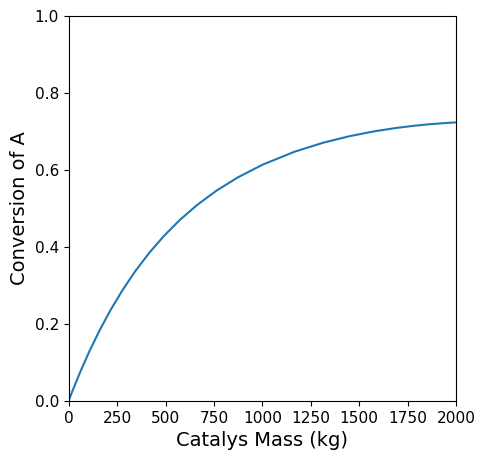

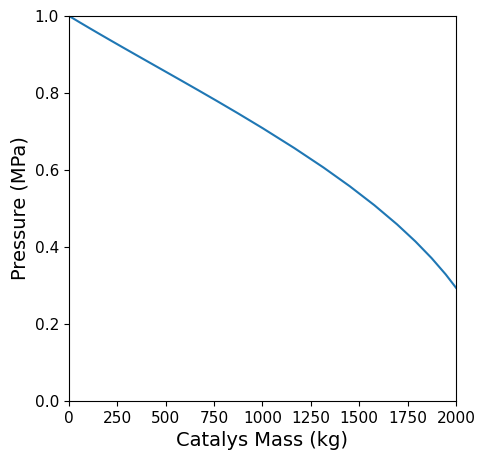

In [33]:
###################################################################
# Defining global constants for Example Problem 02                #
###################################################################

FAf = 100        #mol/s
FBf = 100        #mol/s
FCf = 0          #mol/s
FDf = 0          #mol/s
FTf = FAf + FBf + FCf + FDf
Pf  = 1.0e6      #Pa, 10 bar
R   = 8314       #L*Pa/mol/K
T   = 573        #K
Qf  = FTf*R*T/Pf
k1  = 10         #L^2/mol/kg/sec
k2  = 1          #L^2/mol/kg/sec
Ergun = 303.975  #Pa/kg
XA_target = 0.7

###################################################################
# Define the ODE system for the PBR with pressure drop            #
# function has the form f(W, [FA, FB, FC, FD, P])                 #
# function returns [dFAdW, dFBdW, dFCdW, dFDdW, dPdW]             #
###################################################################

def P03(W, var):
    FA, FB, FC, FD, P = var #all flowrates in mol/s
    FT = FA + FB + FC + FD
    Q = FT*R*T/P       #vol flow rate, L/sec
    CA = FA/Q          #Concentration of A, mol/L
    CB = FB/Q          #Concentration of B, mol/L
    CC = FC/Q          #Concentration of C, mol/L
    CD = FD/Q          #Concentration of D, mol/L
    r1 = k1*CA*CB      #Rate of reaction 1, mol/kg/sec
    r2 = k2*CA**2      #Rate of reaction 2, mol/kg/sec
    RA = -r1 - 2*r2
    RB = -r1
    RC =  r1
    RD =  r2
    dFAdW = RA
    dFBdW = RB
    dFCdW = RC
    dFDdW = RD
    dPdW  = -Ergun*Q/Qf
    return [dFAdW, dFBdW, dFCdW, dFDdW, dPdW]

###################################################################
# Define integration span and starting values for state variables #
###################################################################

wspan = (0, 2000)
var0  = (FAf, FBf, FCf, FDf, Pf)

###################################################################
# Integrate the ODE system using solve_ivp()                      #
###################################################################

ans03 = solve_ivp(P03, wspan, var0, atol = 1e-8, rtol = 1e-8)

###################################################################
# Extract relevant information from the solution structure        #
###################################################################

W   = ans03.t
FA  = ans03.y[0]
P   = ans03.y[4]

###################################################################
# Calculate ethane conversion                                     #
###################################################################

XA  = (FAf - FA)/FAf

###################################################################
# Construct W(XA); find W(0.7)                                    #
###################################################################

itp = interp1d(XA, W, kind = 'cubic')
print(f'The mass of catalyst required to achieve XA = {XA_target:0.2f} is W = {itp(XA_target):0.0f} kg') 

###################################################################
# Graph XA vs W                                                   #
###################################################################

plt.figure(figsize = (5, 5))
plt.plot(W, XA)
plt.xlim(0.0, max(wspan))
plt.xticks(fontsize = 11)
plt.xlabel('Catalys Mass (kg)', fontsize = 14)
plt.ylim(0.0, 1.0)
plt.yticks(fontsize = 11)
plt.ylabel('Conversion of A', fontsize = 14)
plt.show()

###################################################################
# Graph P vs W                                                   #
###################################################################

plt.figure(figsize = (5, 5))
plt.plot(W, P/1e6)
plt.xlim(0.0, max(wspan))
plt.xticks(fontsize = 11)
plt.xlabel('Catalys Mass (kg)', fontsize = 14)
plt.ylim(0, 1.0)
plt.yticks(fontsize = 11)
plt.ylabel('Pressure (MPa)', fontsize = 14)
plt.show()